In [2]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset

df = pd.read_csv("Loan_default.csv")

# Display the first five records

df.head()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [3]:
# Display dataset dimensions

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display column information

df.info()

# Display statistical summary

df.describe()

Number of rows: 255347
Number of columns: 18
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  object 
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  object 
 11  EmploymentType  255347 non-null  object 
 12  MaritalStatus   255347 non-null  object 
 13  HasMortgage     255347 non-null  object 
 14  HasDependents   255347 non-null  object 
 15  LoanPurpose     255347 non-null  object 
 16  HasCoSigner

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000


In [4]:
# Count missing values in each column

missing_values = df.isnull().sum()

print(missing_values)

# Calculate total missing values

print("Total missing values:", missing_values.sum())

LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64
Total missing values: 0


In [5]:
# Check duplicate rows

print("Duplicate rows:", df.duplicated().sum())

# Check duplicate Loan IDs

print("Duplicate Loan IDs:", df["LoanID"].duplicated().sum())

Duplicate rows: 0
Duplicate Loan IDs: 0


In [6]:
# Display data types

print(df.dtypes)

LoanID             object
Age                 int64
Income              int64
LoanAmount          int64
CreditScore         int64
MonthsEmployed      int64
NumCreditLines      int64
InterestRate      float64
LoanTerm            int64
DTIRatio          float64
Education          object
EmploymentType     object
MaritalStatus      object
HasMortgage        object
HasDependents      object
LoanPurpose        object
HasCoSigner        object
Default             int64
dtype: object


In [7]:
# Select numerical columns, excluding the target

numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.drop("Default")

# Detect outliers using IQR

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(column, ":", len(outliers))

Age : 0
Income : 0
LoanAmount : 0
CreditScore : 0
MonthsEmployed : 0
NumCreditLines : 0
InterestRate : 0
LoanTerm : 0
DTIRatio : 0


In [8]:
# Check invalid numerical values

print("Age below 18:",
      (df["Age"] < 18).sum())

print("Income <= 0:",
      (df["Income"] <= 0).sum())

print("LoanAmount <= 0:",
      (df["LoanAmount"] <= 0).sum())

print("Invalid CreditScore:",
      (~df["CreditScore"].between(300, 850)).sum())

print("Negative MonthsEmployed:",
      (df["MonthsEmployed"] < 0).sum())

print("Invalid NumCreditLines:",
      (df["NumCreditLines"] <= 0).sum())

print("Invalid InterestRate:",
      (df["InterestRate"] <= 0).sum())

print("Invalid LoanTerm:",
      (df["LoanTerm"] <= 0).sum())

print("Invalid DTIRatio:",
      (~df["DTIRatio"].between(0, 1)).sum())

print("Invalid Default values:",
      (~df["Default"].isin([0, 1])).sum())

Age below 18: 0
Income <= 0: 0
LoanAmount <= 0: 0
Invalid CreditScore: 0
Negative MonthsEmployed: 0
Invalid NumCreditLines: 0
Invalid InterestRate: 0
Invalid LoanTerm: 0
Invalid DTIRatio: 0
Invalid Default values: 0


In [9]:
# Identify categorical columns

categorical_columns = df.select_dtypes(
    include="object"
).columns.drop("LoanID")

# Display unique values

for column in categorical_columns:

    print("\nColumn:", column)

    print(df[column].unique())


Column: Education
["Bachelor's" "Master's" 'High School' 'PhD']

Column: EmploymentType
['Full-time' 'Unemployed' 'Self-employed' 'Part-time']

Column: MaritalStatus
['Divorced' 'Married' 'Single']

Column: HasMortgage
['Yes' 'No']

Column: HasDependents
['Yes' 'No']

Column: LoanPurpose
['Other' 'Auto' 'Business' 'Home' 'Education']

Column: HasCoSigner
['Yes' 'No']


Default
0    225694
1     29653
Name: count, dtype: int64
Default
0    88.387175
1    11.612825
Name: proportion, dtype: float64


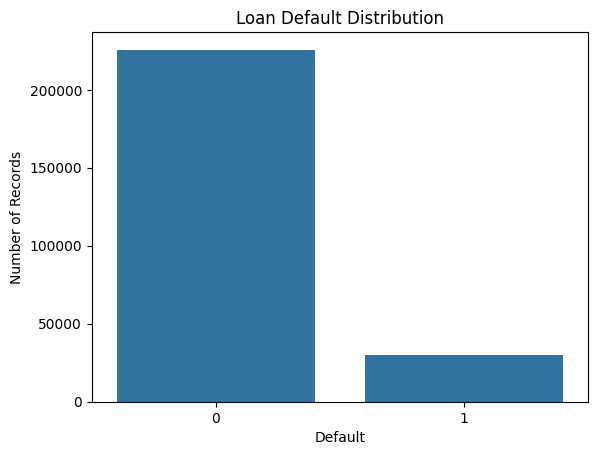

In [10]:
# Count target classes

print(df["Default"].value_counts())

# Calculate percentages

print(
    df["Default"].value_counts(normalize=True) * 100
)

# Visualize target distribution

sns.countplot(data=df, x="Default")

plt.title("Loan Default Distribution")
plt.xlabel("Default")
plt.ylabel("Number of Records")

plt.show()

In [11]:
# Create a copy of the original dataset

cleaned_df = df.copy()

# Remove the unique identifier

cleaned_df = cleaned_df.drop(columns=["LoanID"])

# Check the final dataset

print("Final dataset shape:", cleaned_df.shape)

cleaned_df.head()

Final dataset shape: (255347, 17)


,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


# Stage 4: Exploratory Data Analysis (EDA) and Feature Engineering

This stage focuses on exploring the loan dataset to identify
important patterns, relationships, and trends that may help
understand loan default behavior. It also includes creating
meaningful features that may improve machine learning performance.

In [12]:
# Create a copy of the original dataset
cleaned_df = df.copy()

# Remove LoanID because it is an identifier, not a useful prediction feature
cleaned_df = cleaned_df.drop(columns=["LoanID"])

# Display the dataset dimensions
print("Cleaned dataset shape:", cleaned_df.shape)

Cleaned dataset shape: (255347, 17)


In [13]:
print("Dataset shape:", cleaned_df.shape)

print("\nDataset columns:")
print(cleaned_df.columns.tolist())

print("\nFirst five rows:")
display(cleaned_df.head())

Dataset shape: (255347, 17)

Dataset columns:
['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default']

First five rows:


,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [15]:
# Check the distribution of the target variable

print("Default counts:")
print(cleaned_df["Default"].value_counts())

print("\nDefault percentages:")
print(cleaned_df["Default"].value_counts(normalize=True) * 100)

Default counts:
Default
0    225694
1     29653
Name: count, dtype: int64

Default percentages:
Default
0    88.387175
1    11.612825
Name: proportion, dtype: float64


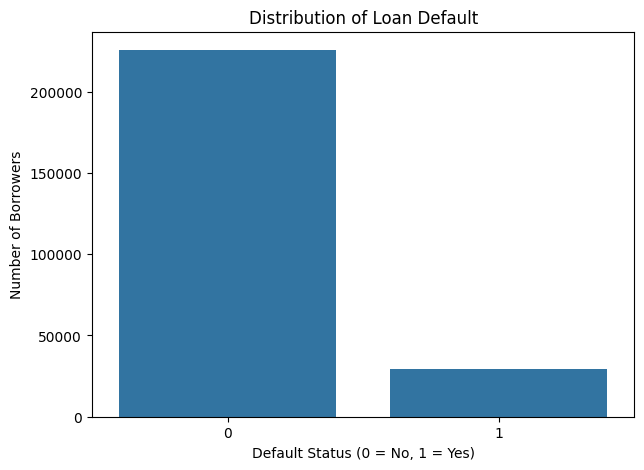

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=cleaned_df, x="Default")

plt.title("Distribution of Loan Default")
plt.xlabel("Default Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Borrowers")

plt.show()

### Key Findings

- The dataset shows a significant class imbalance.
- Approximately 88% of borrowers did not default.
- Approximately 12% of borrowers defaulted.
- Accuracy alone may be misleading.
- Additional evaluation metrics will be used
  to assess model performance.

In [17]:
print(cleaned_df["Default"].value_counts())

print(cleaned_df["Default"].value_counts(
    normalize=True
).mul(100).round(2))

Default
0    225694
1     29653
Name: count, dtype: int64
Default
0    88.39
1    11.61
Name: proportion, dtype: float64


## 4.2 Numerical Feature Analysis

This section examines numerical features to identify
patterns and relationships associated with loan default.
The analysis focuses on age, income, loan amount,
credit score, interest rate, and debt-to-income ratio.

In [18]:
# Select numerical features

numerical_features = [
    "Age",
    "Income",
    "LoanAmount",
    "CreditScore",
    "MonthsEmployed",
    "NumCreditLines",
    "InterestRate",
    "LoanTerm",
    "DTIRatio"
]

# Display descriptive statistics

display(cleaned_df[numerical_features].describe().round(2))

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio
count,255347.00,255347.00,255347.00,255347.00,255347.00,255347.00,255347.00,255347.00,255347.00
mean,43.50,82499.30,127578.87,574.26,59.54,2.50,13.49,36.03,0.50
std,14.99,38963.01,70840.71,158.90,34.64,1.12,6.64,16.97,0.23
min,18.00,15000.00,5000.00,300.00,0.00,1.00,2.00,12.00,0.10
25%,31.00,48825.50,66156.00,437.00,30.00,2.00,7.77,24.00,0.30
50%,43.00,82466.00,127556.00,574.00,60.00,2.00,13.46,36.00,0.50
75%,56.00,116219.00,188985.00,712.00,90.00,3.00,19.25,48.00,0.70
max,69.00,149999.00,249999.00,849.00,119.00,4.00,25.00,60.00,0.90


In [19]:
# Compare average numerical values by default status

comparison = cleaned_df.groupby("Default")[
    numerical_features
].mean().round(2)

display(comparison)

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio
Default,,,,,,,,,
0,44.41,83899.17,125353.66,576.23,60.76,2.49,13.18,36.02,0.50
1,36.56,71844.72,144515.31,559.29,50.24,2.59,15.90,36.05,0.51


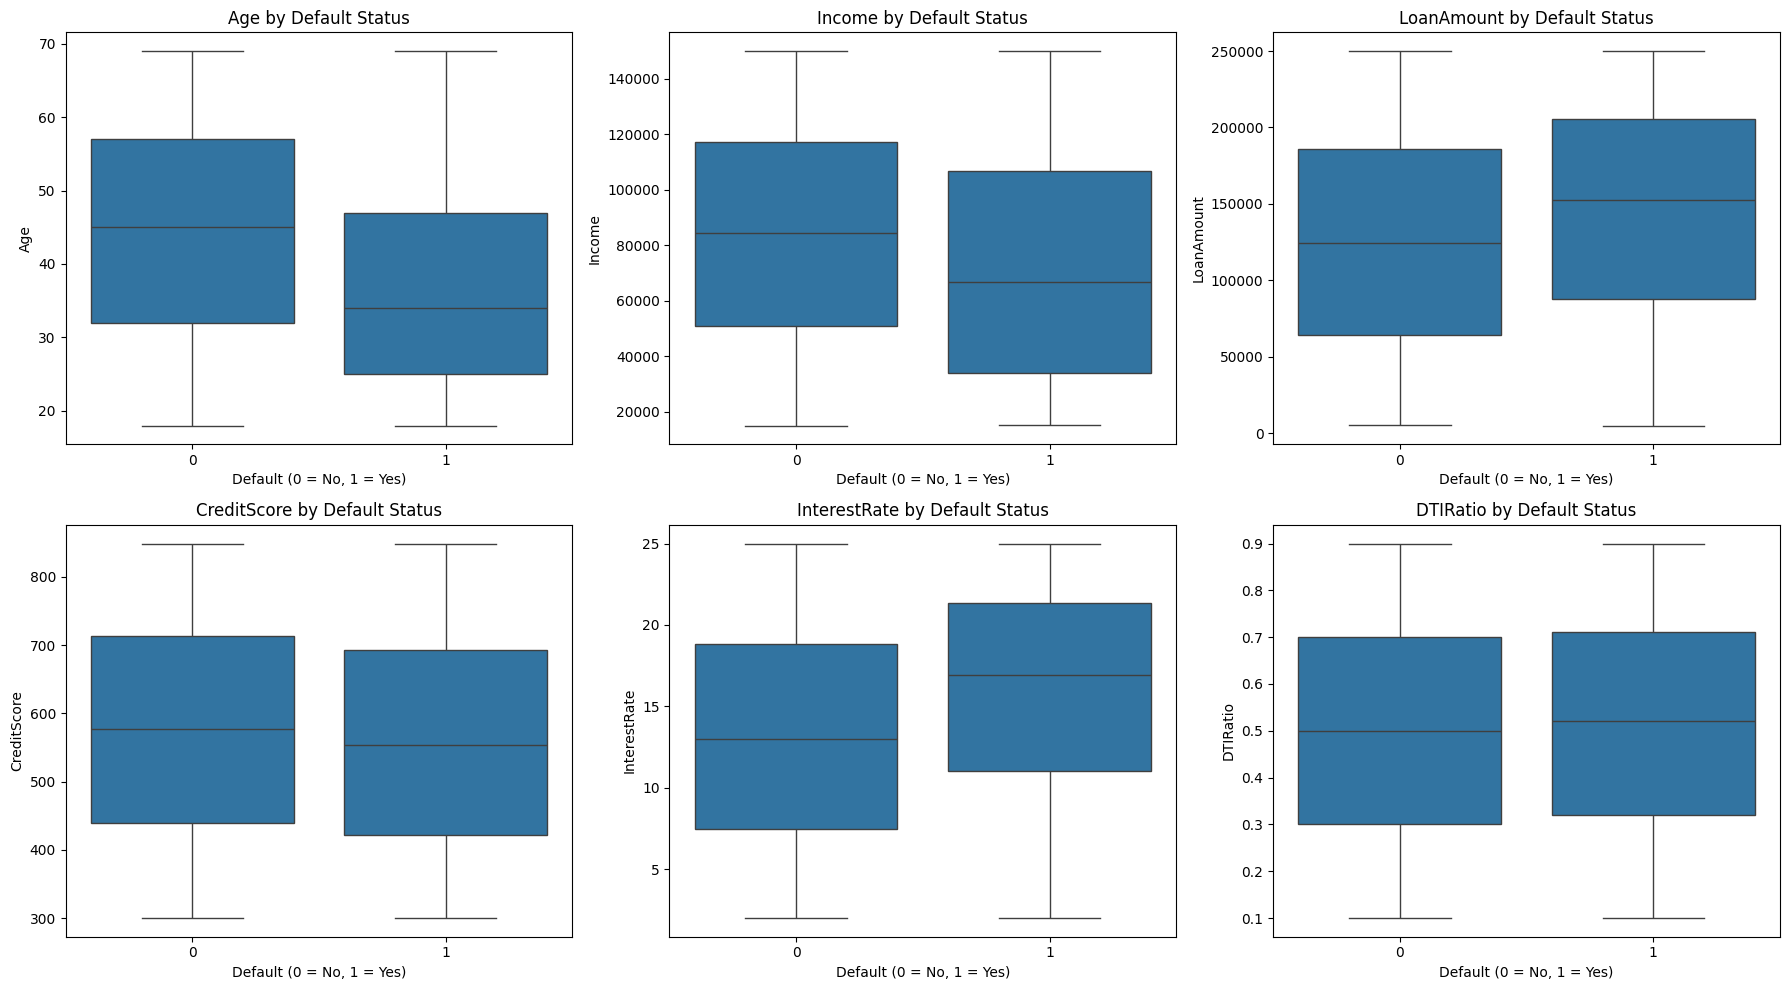

In [20]:
# Visualize numerical features by default status

selected_features = [
    "Age",
    "Income",
    "LoanAmount",
    "CreditScore",
    "InterestRate",
    "DTIRatio"
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for feature, ax in zip(selected_features, axes.flatten()):

    sns.boxplot(
        data=cleaned_df,
        x="Default",
        y=feature,
        ax=ax
    )

    ax.set_title(f"{feature} by Default Status")
    ax.set_xlabel("Default (0 = No, 1 = Yes)")

plt.tight_layout()
plt.show()

In [21]:
display(cleaned_df[numerical_features].describe().round(2))

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio
count,255347.00,255347.00,255347.00,255347.00,255347.00,255347.00,255347.00,255347.00,255347.00
mean,43.50,82499.30,127578.87,574.26,59.54,2.50,13.49,36.03,0.50
std,14.99,38963.01,70840.71,158.90,34.64,1.12,6.64,16.97,0.23
min,18.00,15000.00,5000.00,300.00,0.00,1.00,2.00,12.00,0.10
25%,31.00,48825.50,66156.00,437.00,30.00,2.00,7.77,24.00,0.30
50%,43.00,82466.00,127556.00,574.00,60.00,2.00,13.46,36.00,0.50
75%,56.00,116219.00,188985.00,712.00,90.00,3.00,19.25,48.00,0.70
max,69.00,149999.00,249999.00,849.00,119.00,4.00,25.00,60.00,0.90


In [22]:
comparison = cleaned_df.groupby("Default")[
    numerical_features
].mean().round(2)

display(comparison)

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio
Default,,,,,,,,,
0,44.41,83899.17,125353.66,576.23,60.76,2.49,13.18,36.02,0.50
1,36.56,71844.72,144515.31,559.29,50.24,2.59,15.90,36.05,0.51


## 4.3 Categorical Feature Analysis

This section examines categorical features to identify
differences in loan default rates across borrower groups.
The analysis helps identify potential credit risk patterns
associated with borrower characteristics.

In [24]:
# Identify categorical features

categorical_features = [
    "Education",
    "EmploymentType",
    "MaritalStatus",
    "HasMortgage",
    "HasDependents",
    "LoanPurpose",
    "HasCoSigner"
]

# Display unique categories

for feature in categorical_features:
    print(feature, ":", cleaned_df[feature].unique())

Education : ["Bachelor's" "Master's" 'High School' 'PhD']
EmploymentType : ['Full-time' 'Unemployed' 'Self-employed' 'Part-time']
MaritalStatus : ['Divorced' 'Married' 'Single']
HasMortgage : ['Yes' 'No']
HasDependents : ['Yes' 'No']
LoanPurpose : ['Other' 'Auto' 'Business' 'Home' 'Education']
HasCoSigner : ['Yes' 'No']


In [25]:
# Calculate default rates for each category

for feature in categorical_features:

    default_rates = cleaned_df.groupby(feature)[
        "Default"
    ].mean().mul(100).round(2)

    print("\nDefault Rate by", feature)

    display(default_rates.to_frame("Default Rate (%)"))


Default Rate by Education


,Default Rate (%)
Education,
Bachelor's,12.10
High School,12.88
Master's,10.87
PhD,10.59



Default Rate by EmploymentType


,Default Rate (%)
EmploymentType,
Full-time,9.46
Part-time,11.97
Self-employed,11.46
Unemployed,13.55



Default Rate by MaritalStatus


,Default Rate (%)
MaritalStatus,
Divorced,12.53
Married,10.40
Single,11.91


... (4 outputs left out)


Default Rate by LoanPurpose


,Default Rate (%)
LoanPurpose,
Auto,11.88
Business,12.33
Education,11.84
Home,10.23
Other,11.79



Default Rate by HasCoSigner


,Default Rate (%)
HasCoSigner,
No,12.87
Yes,10.36


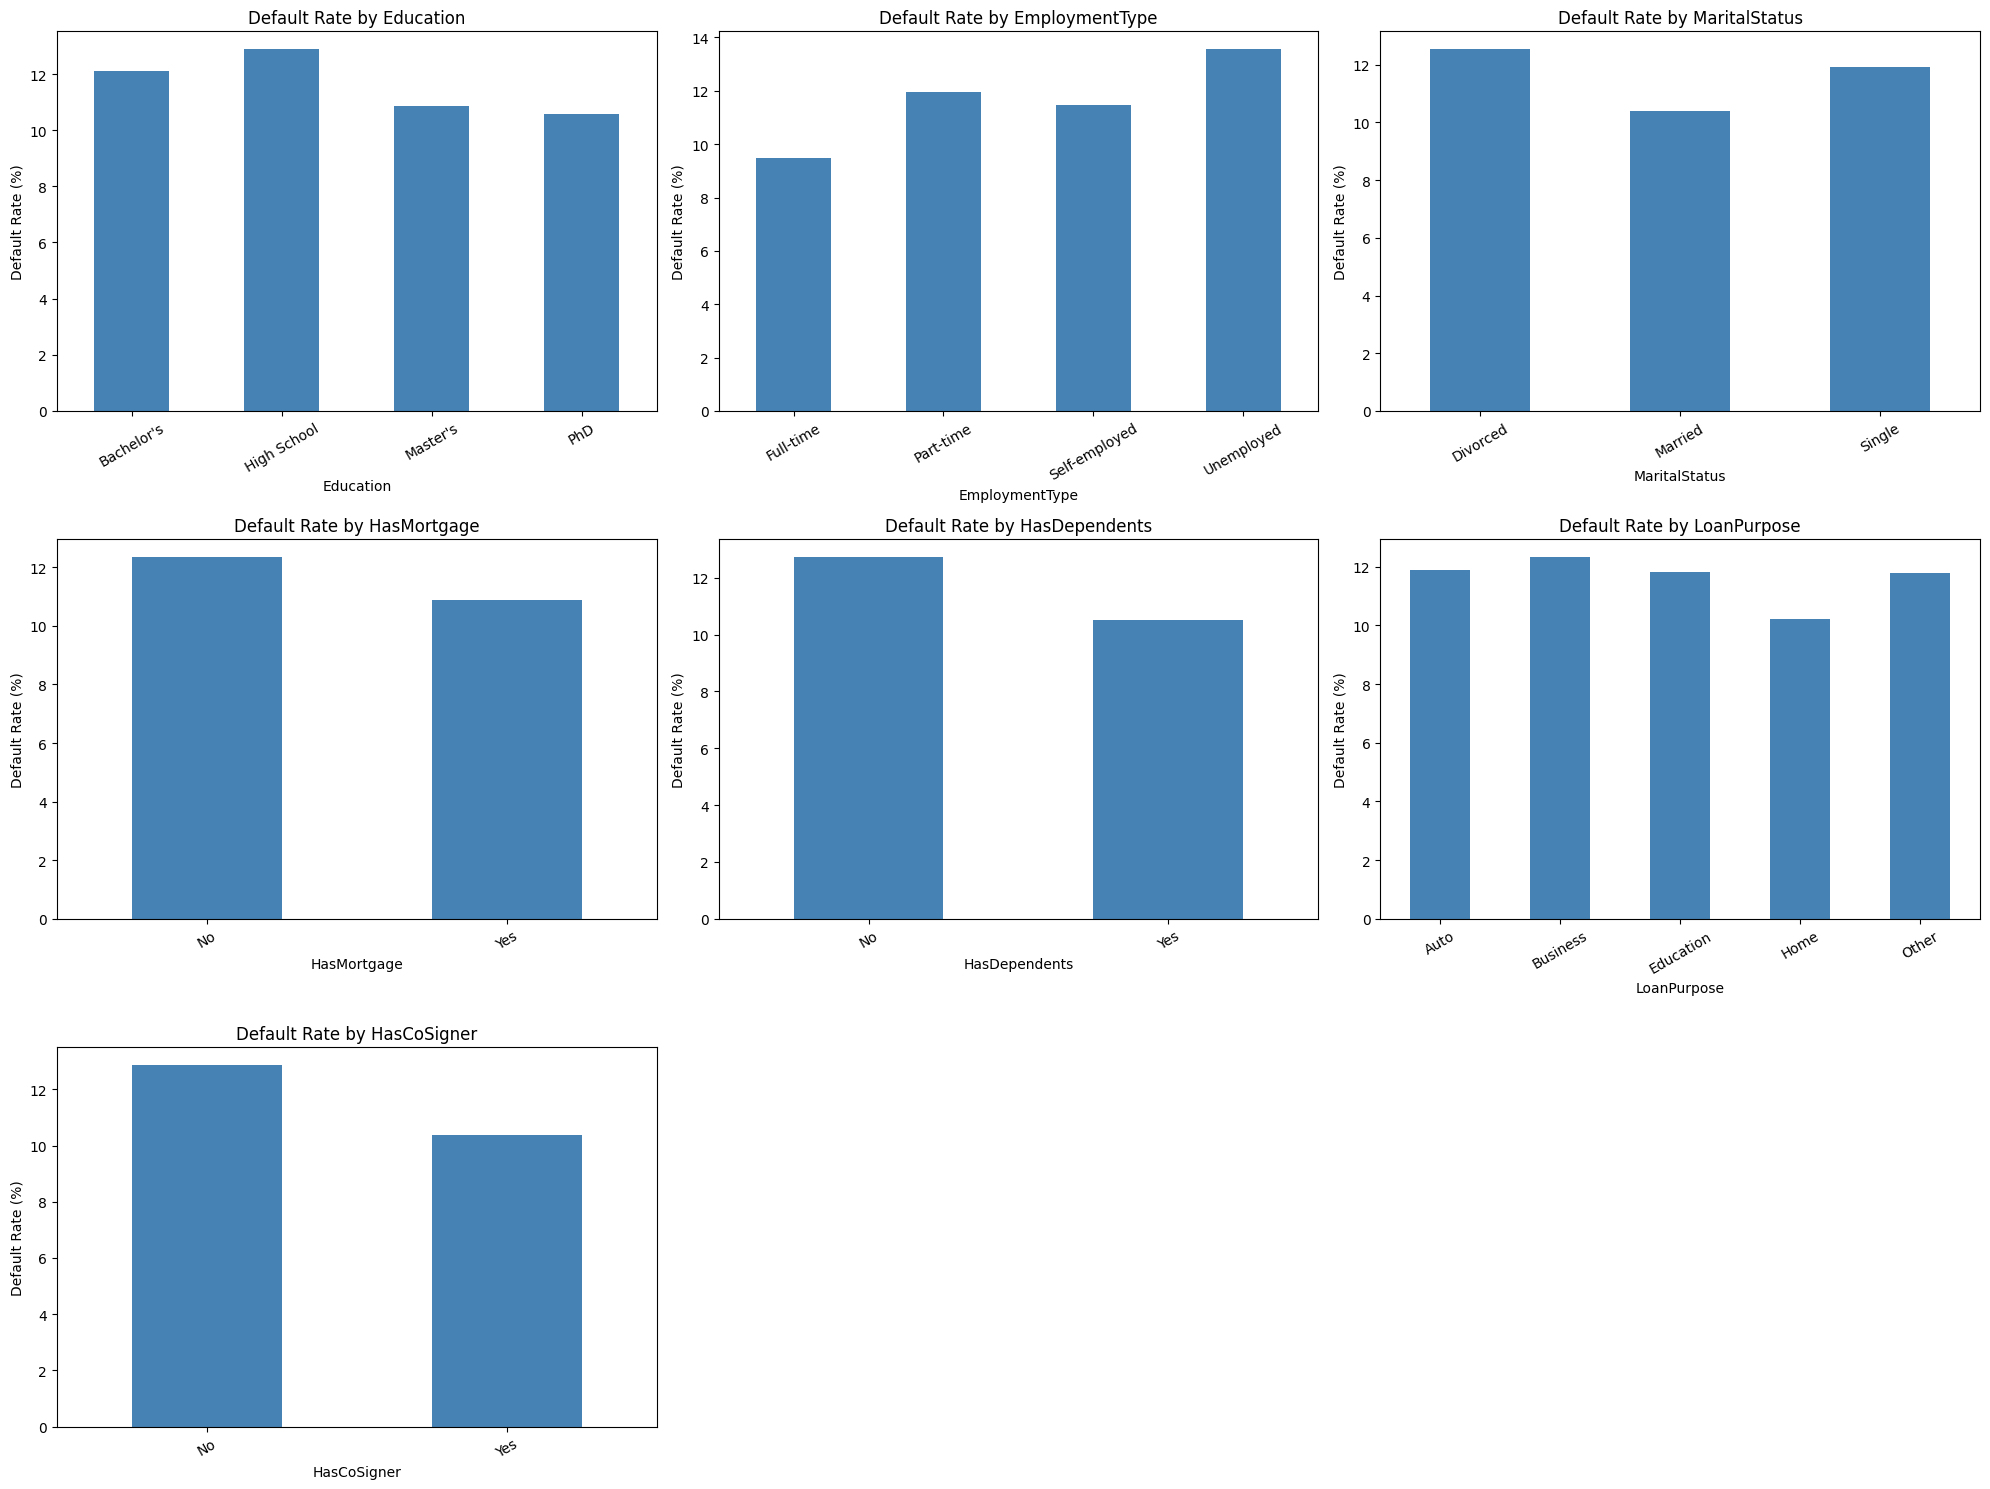

In [26]:
# Visualize default rates by categorical features

fig, axes = plt.subplots(3, 3, figsize=(20, 15))

axes = axes.flatten()

for i, feature in enumerate(categorical_features):

    rates = cleaned_df.groupby(feature)[
        "Default"
    ].mean() * 100

    rates.plot(
        kind="bar",
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(f"Default Rate by {feature}")
    axes[i].set_ylabel("Default Rate (%)")
    axes[i].set_xlabel(feature)
    axes[i].tick_params(axis="x", rotation=30)

# Remove unused plots

for i in range(len(categorical_features), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()

plt.savefig(
    "categorical_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4.4 Correlation Analysis

Correlation analysis is conducted to examine the
strength and direction of linear relationships
between numerical features and loan default.

A correlation heatmap is used to visualize these
relationships and identify potential predictors.

In [27]:
# Select numerical columns

numerical_data = cleaned_df.select_dtypes(
    include=["number"]
)

# Calculate Pearson correlation

correlation_matrix = numerical_data.corr()

# Display correlation matrix

display(correlation_matrix.round(3))

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
Age,1.000,-0.001,-0.002,-0.001,-0.000,-0.001,-0.001,0.000,-0.005,-0.168
Income,-0.001,1.000,-0.001,-0.001,0.003,-0.002,-0.002,-0.001,0.000,-0.099
LoanAmount,-0.002,-0.001,1.000,0.001,0.003,0.001,-0.002,0.003,0.001,0.087
CreditScore,-0.001,-0.001,0.001,1.000,0.001,0.000,0.000,0.001,-0.001,-0.034
MonthsEmployed,-0.000,0.003,0.003,0.001,1.000,0.001,0.000,-0.001,0.002,-0.097
NumCreditLines,-0.001,-0.002,0.001,0.000,0.001,1.000,-0.000,-0.000,-0.001,0.028
InterestRate,-0.001,-0.002,-0.002,0.000,0.000,-0.000,1.000,0.001,0.001,0.131
LoanTerm,0.000,-0.001,0.003,0.001,-0.001,-0.000,0.001,1.000,0.002,0.001
DTIRatio,-0.005,0.000,0.001,-0.001,0.002,-0.001,0.001,0.002,1.000,0.019
Default,-0.168,-0.099,0.087,-0.034,-0.097,0.028,0.131,0.001,0.019,1.000


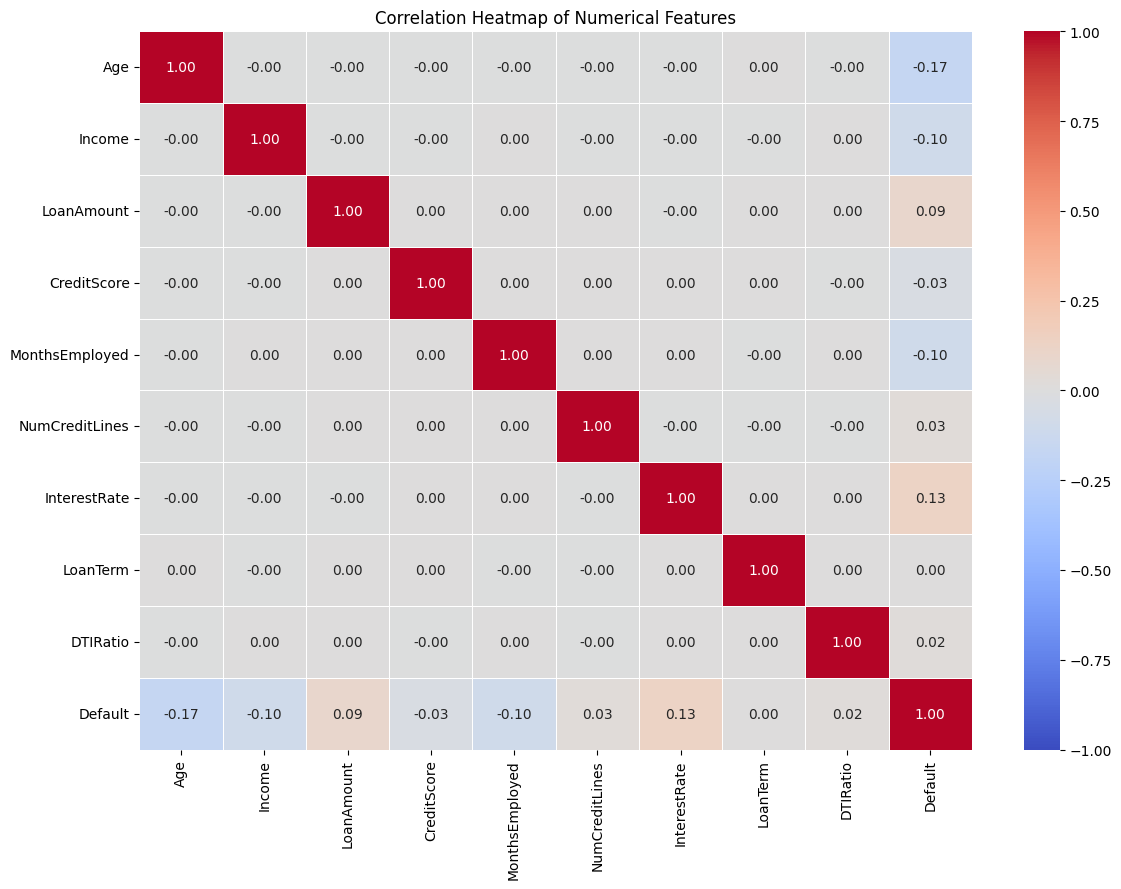

In [28]:
# Visualize the correlation matrix

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")

plt.tight_layout()

plt.savefig(
    "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [29]:
# Calculate correlations with the target variable

default_correlation = correlation_matrix[
    "Default"
].drop("Default")

# Sort by absolute correlation strength

default_correlation = default_correlation.sort_values(
    key=abs,
    ascending=False
)

display(
    default_correlation.round(4).to_frame(
        "Correlation with Default"
    )
)

,Correlation with Default
Age,-0.1678
InterestRate,0.1313
Income,-0.0991
MonthsEmployed,-0.0974
LoanAmount,0.0867
CreditScore,-0.0342
NumCreditLines,0.0283
DTIRatio,0.0192
LoanTerm,0.0005


## 4.5 Feature Engineering

Feature engineering is performed to create meaningful
financial features from existing variables.

The objective is to provide additional information
that may improve the predictive performance of
machine learning models.

In [30]:
# Create a copy of the cleaned dataset

engineered_df = cleaned_df.copy()

# Feature 1: Loan-to-income ratio

engineered_df["LoanToIncomeRatio"] = (
    engineered_df["LoanAmount"] /
    engineered_df["Income"]
)

# Feature 2: Estimated monthly income

engineered_df["MonthlyIncome"] = (
    engineered_df["Income"] / 12
)

# Feature 3: Estimated monthly principal

engineered_df["EstimatedMonthlyPrincipal"] = (
    engineered_df["LoanAmount"] /
    engineered_df["LoanTerm"]
)

# Display the new features

display(engineered_df[
    [
        "LoanToIncomeRatio",
        "MonthlyIncome",
        "EstimatedMonthlyPrincipal"
    ]
].head().round(2))

,LoanToIncomeRatio,MonthlyIncome,EstimatedMonthlyPrincipal
0,0.59,7166.17,1405.19
1,2.47,4202.67,2074.00
2,1.53,7017.33,5382.83
3,1.41,2642.75,1866.62
4,0.45,1703.08,190.40


In [31]:
import numpy as np

# Select newly engineered features

new_features = [
    "LoanToIncomeRatio",
    "MonthlyIncome",
    "EstimatedMonthlyPrincipal"
]

# Check missing values

print("Missing values:")
print(engineered_df[new_features].isnull().sum())

# Check infinite values

print("\nInfinite values:")
print(np.isinf(engineered_df[new_features]).sum())

# Display summary statistics

display(engineered_df[new_features].describe().round(2))

# Display final dataset dimensions

print("\nOriginal cleaned dataset:", cleaned_df.shape)

print("Engineered dataset:", engineered_df.shape)

Missing values:
LoanToIncomeRatio            0
MonthlyIncome                0
EstimatedMonthlyPrincipal    0
dtype: int64

Infinite values:
LoanToIncomeRatio            0
MonthlyIncome                0
EstimatedMonthlyPrincipal    0
dtype: int64


,LoanToIncomeRatio,MonthlyIncome,EstimatedMonthlyPrincipal
count,255347.00,255347.00,255347.00
mean,2.18,6874.94,4845.98
std,2.18,3246.92,4431.09
min,0.03,1250.00,83.43
25%,0.80,4068.79,1841.79
50%,1.55,6872.17,3537.42
75%,2.67,9684.92,6147.96
max,16.53,12499.92,20832.75



Original cleaned dataset: (255347, 17)
Engineered dataset: (255347, 20)


In [32]:
# Compare engineered features by default status

engineered_comparison = engineered_df.groupby(
    "Default"
)[new_features].mean().round(2)

display(engineered_comparison)

,LoanToIncomeRatio,MonthlyIncome,EstimatedMonthlyPrincipal
Default,,,
0,2.04,6991.60,4759.8
1,3.25,5987.06,5501.9


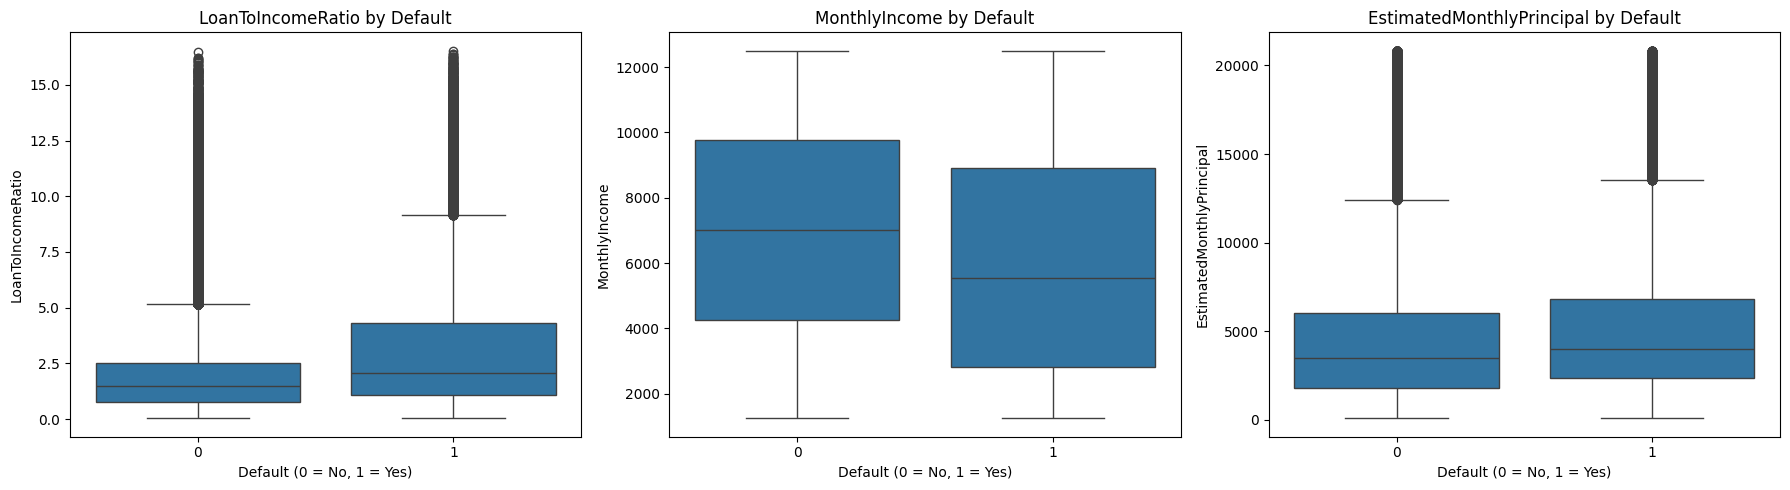

In [33]:
# Visualize engineered features

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for feature, ax in zip(new_features, axes):

    sns.boxplot(
        data=engineered_df,
        x="Default",
        y=feature,
        ax=ax
    )

    ax.set_title(f"{feature} by Default")
    ax.set_xlabel("Default (0 = No, 1 = Yes)")

plt.tight_layout()

plt.savefig(
    "feature_engineering.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4.6 Business Insights and Summary

- The dataset contains 255,347 loan records.
- 88.39% of borrowers did not default.
- 11.61% of borrowers defaulted.
- The dataset demonstrates class imbalance.
- Numerical and categorical features were analyzed
  to investigate potential credit risk indicators.
- Correlation analysis was performed to examine
  relationships between numerical variables.
- Three additional financial features were created.
- Accuracy alone is insufficient for model evaluation.
- The dataset will be used to develop and compare
  machine learning classification models.

In [35]:
# Save the engineered dataset

engineered_df.to_csv(
    "Loan_Engineered.csv",
    index=False
)

print("Dataset saved successfully!")
print("Final dataset shape:", engineered_df.shape)

Dataset saved successfully!
Final dataset shape: (255347, 20)
